In [71]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

df = pd.read_csv("india_district_crop_dataset_1997_2015.xls")
df.head()

C:\Users\anjanbabu aluvala\AppData\Local\Temp\ipykernel_12312\1426711779.py:7: DtypeWarning: Columns (29) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("india_district_crop_dataset_1997_2015.xls")


,district_key,Dist_LGD,state,district,crop_year,season,centroid_lat,centroid_lon,elevation_m,soil_ph_h2o_0_5cm,...,annual_rainfall_mm,annual_temp_mean_c,annual_humidity_pct,dominant_crop,dominant_share,dominant_yield,top3_crops,crops_share_ge_10pct,n_crops,total_area_ha
0,01_001,8.0,JAMMU & KASHMIR,Kupwara,1997,Kharif,34.513902,74.191869,2569.63,6.291844,...,416.55,9.150000,52.292500,Maize,0.556723,0.555709,Maize|Rice,Maize|Rice,2,39111.0
1,01_001,8.0,JAMMU & KASHMIR,Kupwara,1999,Kharif,34.513902,74.191869,2569.63,6.291844,...,338.36,9.957500,43.708333,Maize,0.704549,0.190690,Maize|Rice,Maize|Rice,2,33569.0
2,01_001,8.0,JAMMU & KASHMIR,Kupwara,2000,Kharif,34.513902,74.191869,2569.63,6.291844,...,315.25,10.174167,42.490000,Maize,0.681621,0.749087,Maize|Rice,Maize|Rice,2,35351.0
3,01_001,8.0,JAMMU & KASHMIR,Kupwara,2000,Rabi,34.513902,74.191869,2569.63,6.291844,...,315.25,10.174167,42.490000,Rapeseed &Mustard,0.952065,0.391944,Rapeseed &Mustard|Wheat,Rapeseed &Mustard,2,2712.0
4,01_001,8.0,JAMMU & KASHMIR,Kupwara,2001,Kharif,34.513902,74.191869,2569.63,6.291844,...,475.91,9.956667,48.040833,Maize,0.668728,0.742812,Maize|Rice,Maize|Rice,2,35572.0


In [72]:
df.shape

(34903, 48)

In [73]:
df.describe()

,Dist_LGD,crop_year,centroid_lat,centroid_lon,elevation_m,soil_ph_h2o_0_5cm,soil_ph_h2o_0_30cm,soil_total_n_g_kg_0_5cm,soil_total_n_g_kg_0_30cm,soil_soc_g_kg_0_5cm,...,rain_days_proxy_mm_per_day,solar_mj_m2_day,wind_m_s,annual_rainfall_mm,annual_temp_mean_c,annual_humidity_pct,dominant_share,dominant_yield,n_crops,total_area_ha
count,34903.000000,34903.000000,34903.000000,34903.000000,34903.000000,34903.000000,34903.000000,34903.000000,34903.000000,34903.000000,...,34903.000000,34903.000000,34903.000000,34903.000000,34903.000000,34903.000000,34903.000000,34858.000000,34903.000000,3.490300e+04
mean,318.619374,2005.443859,23.199776,81.864704,390.564708,6.694332,6.724792,2.162271,1.703660,24.449476,...,2.899917,17.847737,1.902079,1192.272460,24.728667,60.121783,0.722444,38.467778,6.487637,7.954490e+04
std,169.216370,5.022075,5.420027,6.297779,563.654101,0.795558,0.807842,1.241444,1.200054,13.830296,...,2.924152,2.796560,0.794915,592.115616,3.764479,12.451886,0.232086,1491.970351,4.750296,1.224781e+05
min,1.000000,1997.000000,6.999949,69.620918,0.410000,5.052396,5.049896,0.422353,0.416032,4.518333,...,0.000000,8.254000,0.034000,52.130000,-8.996667,24.430000,0.090822,0.000000,1.000000,2.800000e-01
25%,187.000000,2001.000000,20.761382,76.740991,107.640000,6.149109,6.181661,1.423959,1.033219,14.999382,...,0.520000,15.796333,1.502000,774.400000,24.480833,50.982500,0.520975,0.972826,2.000000,3.700000e+03
50%,304.000000,2005.000000,24.817213,80.323705,230.320000,6.857303,6.911154,1.679085,1.265714,21.008684,...,2.131667,17.766667,1.882000,1073.220000,25.630833,60.150000,0.748031,1.863378,6.000000,2.418900e+04
75%,465.000000,2010.000000,26.626942,86.331735,447.830000,7.255997,7.291406,2.286852,1.918155,28.344474,...,4.378000,19.380000,2.325417,1484.590000,26.430000,70.551667,0.957726,3.301065,9.000000,1.100570e+05
max,678.000000,2015.000000,34.707282,96.842432,5243.700000,8.770687,8.808253,8.802817,10.579747,87.319701,...,28.204000,26.430000,6.166000,4785.610000,28.947500,85.925833,1.000000,88000.000000,42.000000,1.337325e+06


In [74]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34903 entries, 0 to 34902
Data columns (total 48 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   district_key                     34903 non-null  object 
 1   Dist_LGD                         34903 non-null  float64
 2   state                            34903 non-null  object 
 3   district                         34903 non-null  object 
 4   crop_year                        34903 non-null  int64  
 5   season                           34903 non-null  object 
 6   centroid_lat                     34903 non-null  float64
 7   centroid_lon                     34903 non-null  float64
 8   elevation_m                      34903 non-null  float64
 9   soil_ph_h2o_0_5cm                34903 non-null  float64
 10  soil_ph_h2o_0_30cm               34903 non-null  float64
 11  soil_total_n_g_kg_0_5cm          34903 non-null  float64
 12  soil_total_n_g_kg_

In [75]:
df.isnull().sum()

district_key                           0
Dist_LGD                               0
state                                  0
district                               0
crop_year                              0
season                                 0
centroid_lat                           0
centroid_lon                           0
elevation_m                            0
soil_ph_h2o_0_5cm                      0
soil_ph_h2o_0_30cm                     0
soil_total_n_g_kg_0_5cm                0
soil_total_n_g_kg_0_30cm               0
soil_soc_g_kg_0_5cm                    0
soil_soc_g_kg_0_30cm                   0
soil_cec_cmol_kg_0_5cm                 0
soil_cec_cmol_kg_0_30cm                0
soil_clay_pct_0_5cm                    0
soil_clay_pct_0_30cm                   0
soil_sand_pct_0_5cm                    0
soil_sand_pct_0_30cm                   0
soil_silt_pct_0_5cm                    0
soil_silt_pct_0_30cm                   0
soil_bulk_density_kg_dm3_0_5cm         0
soil_bulk_densit

In [76]:
df.duplicated().sum()

np.int64(0)

In [77]:
df['dominant_crop'].value_counts().head(15)

dominant_crop
Rice                 10587
Wheat                 4696
Sugarcane             2720
Maize                 2158
Potato                1609
Rapeseed &Mustard     1432
Groundnut              900
Bajra                  768
Gram                   752
Jowar                  718
Cotton(lint)           659
Jute                   649
Moong(Green Gram)      641
Dry chillies           636
Soyabean               573
Name: count, dtype: int64

In [78]:
top_crops = df['dominant_crop'].value_counts().head(15).index
df = df[df['dominant_crop'].isin(top_crops)]

In [79]:
num_cols = [
    'soil_ph_h2o_0_30cm',
    'soil_total_n_g_kg_0_30cm',
    'soil_soc_g_kg_0_30cm',
    'soil_clay_pct_0_30cm',
    'soil_sand_pct_0_30cm',
    'temp_mean_c',
    'humidity_pct',
    'rainfall_mm',
    'elevation_m'
]
df['crop_year'] = pd.to_numeric(df['crop_year'], errors='coerce')
df = df.dropna(subset=num_cols + ['season', 'dominant_crop', 'crop_year'])
x = df[num_cols + ['season']]
y = df['dominant_crop']
x = pd.get_dummies(x, columns=['season'])

In [80]:
x.head()

,soil_ph_h2o_0_30cm,soil_total_n_g_kg_0_30cm,soil_soc_g_kg_0_30cm,soil_clay_pct_0_30cm,soil_sand_pct_0_30cm,temp_mean_c,humidity_pct,rainfall_mm,elevation_m,season_Autumn,season_Kharif,season_Rabi,season_Summer,season_Whole Year,season_Winter
0,6.313881,2.784153,38.155486,27.710507,31.758615,16.266,50.618,185.95,2569.63,False,True,False,False,False,False
1,6.313881,2.784153,38.155486,27.710507,31.758615,16.974,42.338,124.96,2569.63,False,True,False,False,False,False
2,6.313881,2.784153,38.155486,27.710507,31.758615,16.952,43.184,100.02,2569.63,False,True,False,False,False,False
3,6.313881,2.784153,38.155486,27.710507,31.758615,1.916,42.032,129.87,2569.63,False,False,True,False,False,False
4,6.313881,2.784153,38.155486,27.710507,31.758615,16.412,50.662,216.27,2569.63,False,True,False,False,False,False


In [81]:
x.shape

(29498, 15)

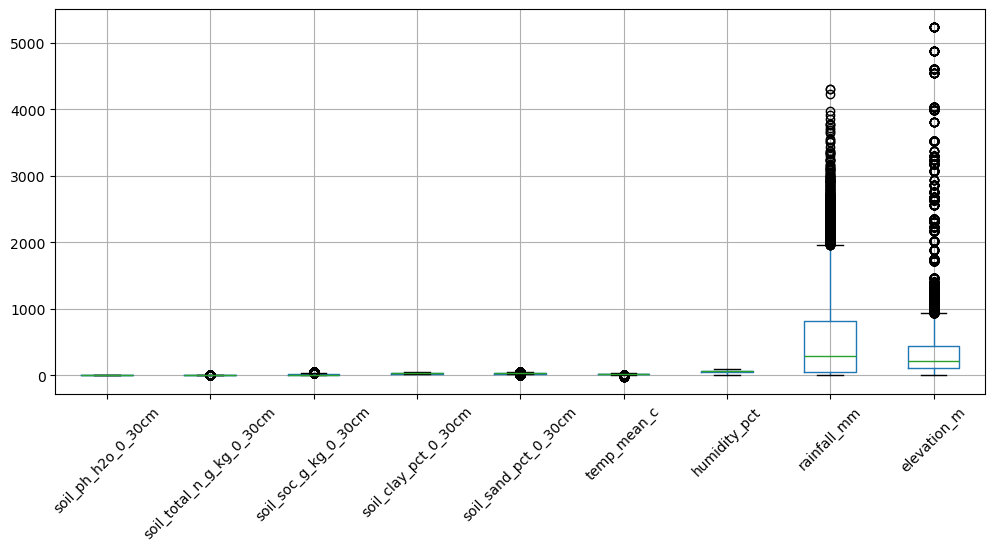

In [82]:
x[num_cols].boxplot(figsize=(12, 5))
plt.xticks(rotation=45)
plt.show()

In [83]:
for col in num_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lwr = q1 - 1.5 * iqr
    upr = q3 + 1.5 * iqr
    outliers = ((df[col] < lwr) | (df[col] > upr)).sum()
    print(col, outliers)

soil_ph_h2o_0_30cm 0
soil_total_n_g_kg_0_30cm 2550
soil_soc_g_kg_0_30cm 2212
soil_clay_pct_0_30cm 0
soil_sand_pct_0_30cm 852
temp_mean_c 554
humidity_pct 0
rainfall_mm 613
elevation_m 2177


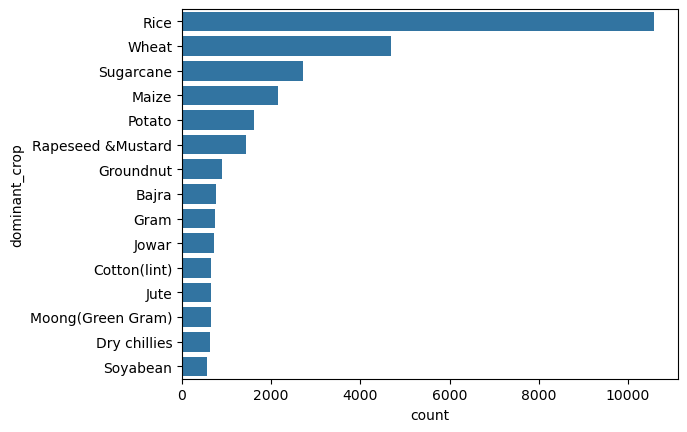

In [84]:
sns.countplot(y='dominant_crop', data=df, order=df['dominant_crop'].value_counts().index)
plt.show()

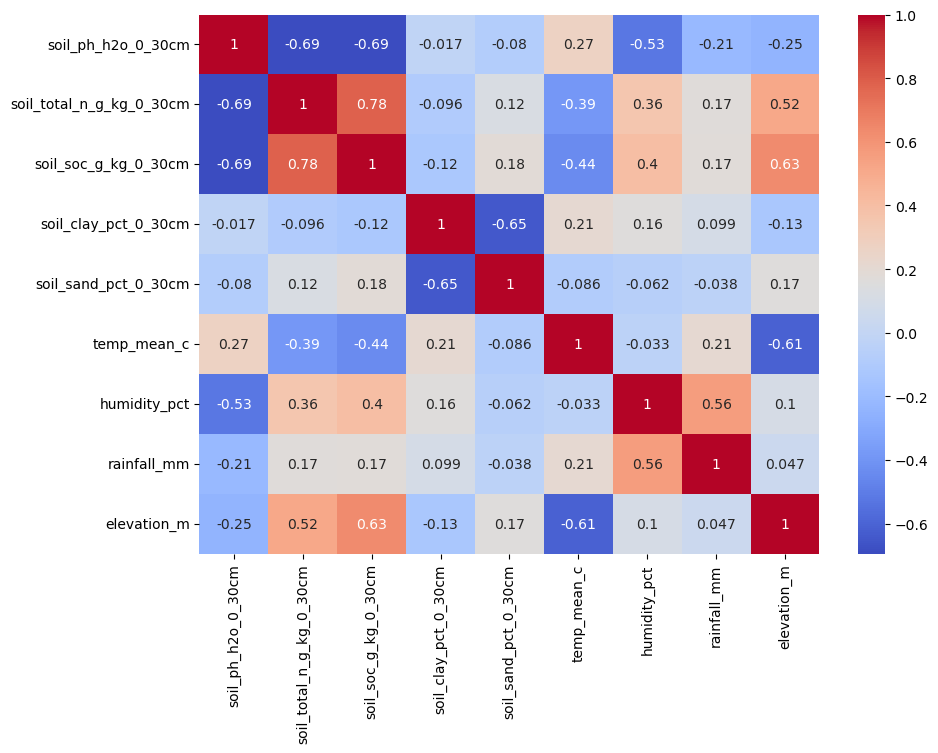

In [85]:
plt.figure(figsize=(10, 7))
sns.heatmap(df[num_cols].corr(), annot=True, cmap='coolwarm')
plt.show()

In [86]:
train_mask = df['crop_year'] <= 2012
test_mask = df['crop_year'] >= 2013
print("Training records:", train_mask.sum())
print("Testing records:", test_mask.sum())

x_train = x.loc[train_mask]
x_test = x.loc[test_mask]
y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

Training records: 26574
Testing records: 2924


In [87]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rf = RandomForestClassifier(n_estimators=100,class_weight='balanced',random_state=42)
rf.fit(x_train_scaled, y_train)
y_pred_rf = rf.predict(x_test_scaled)
rf_acc = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf, average='macro', zero_division=0)
rf_recall = recall_score(y_test, y_pred_rf, average='macro', zero_division=0)
rf_f1 = f1_score(y_test, y_pred_rf, average='macro', zero_division=0)
rf_cv = cross_val_score(rf, x_train_scaled, y_train, cv=cv, scoring='accuracy').mean()
print("Accuracy:", rf_acc)
print("Precision:", rf_precision)
print("Recall:", rf_recall)
print("F1 score:", rf_f1)
print("CV score:", rf_cv)

Accuracy: 0.8255813953488372
Precision: 0.7335410111935807
Recall: 0.7239642811752595
F1 score: 0.7132239394677484
CV score: 0.8687439380737298


In [88]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(class_weight='balanced',random_state=42)
dt.fit(x_train_scaled, y_train)
y_pred_dt = dt.predict(x_test_scaled)
dt_acc = accuracy_score(y_test, y_pred_dt)
dt_precision = precision_score(y_test, y_pred_dt, average='macro', zero_division=0)
dt_recall = recall_score(y_test, y_pred_dt, average='macro', zero_division=0)
dt_f1 = f1_score(y_test, y_pred_dt, average='macro', zero_division=0)
dt_cv = cross_val_score(dt, x_train_scaled, y_train, cv=cv, scoring='accuracy').mean()
print("Accuracy:", dt_acc)
print("Precision:", dt_precision)
print("Recall:", dt_recall)
print("F1 score:", dt_f1)
print("CV score:", dt_cv)

Accuracy: 0.7917236662106704
Precision: 0.6605470153832138
Recall: 0.6452947259948114
F1 score: 0.6387597612008502
CV score: 0.8340860029648869


In [89]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(x_train_scaled, y_train)
y_pred_knn = knn.predict(x_test_scaled)
knn_acc = accuracy_score(y_test, y_pred_knn)
knn_precision = precision_score(y_test, y_pred_knn, average='macro', zero_division=0)
knn_recall = recall_score(y_test, y_pred_knn, average='macro', zero_division=0)
knn_f1 = f1_score(y_test, y_pred_knn, average='macro', zero_division=0)
knn_cv = cross_val_score(knn, x_train_scaled, y_train, cv=cv, scoring='accuracy').mean()
print("Accuracy:", knn_acc)
print("Precision:", knn_precision)
print("Recall:", knn_recall)
print("F1 score:", knn_f1)
print("CV score:", knn_cv)

Accuracy: 0.8067715458276333
Precision: 0.7012578764554346
Recall: 0.7011597575440565
F1 score: 0.6846725048312291
CV score: 0.8511701885468407


In [90]:
results = pd.DataFrame({
    'model': ['Random Forest', 'Decision Tree', 'knn'],
    'accuracy': [rf_acc, dt_acc, knn_acc],
    'precision': [rf_precision, dt_precision, knn_precision],
    'recall': [rf_recall, dt_recall, knn_recall],
    'f1 score': [rf_f1, dt_f1, knn_f1],
    'cv score': [rf_cv, dt_cv, knn_cv],
    'train accuracy': [
        rf.score(x_train_scaled, y_train),
        dt.score(x_train_scaled, y_train),
        knn.score(x_train_scaled, y_train),
    ]
})

results['gap'] = results['train accuracy'] - results['accuracy']
results.round(3)

,model,accuracy,precision,recall,f1 score,cv score,train accuracy,gap
0,Random Forest,0.826,0.734,0.724,0.713,0.869,1.000,0.174
1,Decision Tree,0.792,0.661,0.645,0.639,0.834,1.000,0.208
2,knn,0.807,0.701,0.701,0.685,0.851,0.897,0.091


In [91]:
models = {
    'random forest': rf,
    'decision tree': dt,
    'knn': knn
}

eligible = results[results['gap'] <= 0.10]

if len(eligible) > 0:
    best_index = eligible['cv score'].idxmax()
else:
    best_index = results['cv score'].idxmax()

best_name = results.loc[best_index, 'model']
best_model = models[best_name]

print("Best model:", best_name)
print("CV macro f1:", results.loc[best_index, 'cv score'])
print("Test f1 score:", results.loc[best_index, 'f1 score'])
print("Test accuracy:", results.loc[best_index, 'accuracy'])
print("Overfitting gap:", results.loc[best_index, 'gap'])

Best model: knn
CV macro f1: 0.8511701885468407
Test f1 score: 0.6846725048312291
Test accuracy: 0.8067715458276333
Overfitting gap: 0.09060935279508064


In [92]:
from sklearn.calibration import CalibratedClassifierCV

calibrated_model = CalibratedClassifierCV(
    estimator=best_model,
    method='sigmoid',
    cv=5
)
calibrated_model.fit(x_train_scaled, y_train)

,estimator,KNeighborsClassifier()
,method,'sigmoid'
,cv,5
,n_jobs,None
,ensemble,'auto'
,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'


In [93]:
from sklearn.ensemble import IsolationForest

iso = IsolationForest(contamination=0.02, random_state=42)
iso.fit(x_train_scaled)

,n_estimators,100
,max_samples,'auto'
,contamination,0.02
,max_features,1.0
,bootstrap,False
,n_jobs,None
,random_state,42
,verbose,0
,warm_start,False


In [94]:
minimum = x_train.min()
maximum = x_train.max()

sample = x_test.iloc[[0]]
sample_scaled = scaler.transform(sample)

if ((sample < minimum) | (sample > maximum)).any(axis=1).iloc[0]:
    print("out of range input detected")
elif iso.predict(sample_scaled)[0] == -1:
    print("unusual input combination detected")
else:
    probabilities = calibrated_model.predict_proba(sample_scaled)[0]
    classes = calibrated_model.classes_
    top_indices = np.argsort(probabilities)[::-1][:3]
    print("top 3 crop recommendations")
    for i in top_indices:
        print(classes[i], round(probabilities[i] * 100, 2), "%")

top 3 crop recommendations
Rice 30.86 %
Maize 29.75 %
Sugarcane 7.21 %


In [95]:
joblib.dump({
    'model': calibrated_model,
    'scaler': scaler,
    'iso': iso,
    'features': x.columns.tolist(),
    'num_cols': num_cols,
    'minimum': minimum,
    'maximum': maximum
}, "crop_model_bundle.joblib")

print("All models saved successfully")

All models saved successfully
